# Store Sales — Step 1: Exploratory Data Analysis (EDA)

**Author:** Bella Ren

Goal: understand the data before modeling. Each section answers one question; the summary table at the end drives the data-processing and modeling decisions.

**Data:** download the competition files into `kaggle_comp/data/` (not tracked in git):
`kaggle competitions download store-sales-time-series-forecasting -p kaggle_comp/data --unzip`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams['figure.figsize'] = (14, 4)
plt.rcParams['axes.grid'] = True
DATA = '../data/'

train = pd.read_csv(DATA + 'train.csv', parse_dates=['date'])
test = pd.read_csv(DATA + 'test.csv', parse_dates=['date'])
stores = pd.read_csv(DATA + 'stores.csv')
oil = pd.read_csv(DATA + 'oil.csv', parse_dates=['date'])
hol = pd.read_csv(DATA + 'holidays_events.csv', parse_dates=['date'])
trans = pd.read_csv(DATA + 'transactions.csv', parse_dates=['date'])
train.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


## 1. Overview: size, date range, missing dates

In [2]:
print('train:', train.shape, train.date.min().date(), '->', train.date.max().date())
print('test :', test.shape, test.date.min().date(), '->', test.date.max().date())
print('stores:', train.store_nbr.nunique(), '| families:', train.family.nunique(),
      '| series:', train.groupby(['store_nbr', 'family']).ngroups)

full = pd.date_range(train.date.min(), train.date.max())
missing = full.difference(train.date.unique())
print('Dates missing from train:', [d.date() for d in missing])

train: (3000888, 6) 2013-01-01 -> 2017-08-15
test : (28512, 5) 2017-08-16 -> 2017-08-31
stores: 54 | families: 33 | series: 1782
Dates missing from train: [datetime.date(2013, 12, 25), datetime.date(2014, 12, 25), datetime.date(2015, 12, 25), datetime.date(2016, 12, 25)]


## 2. Total sales trend: is there a trend? any anomalies?

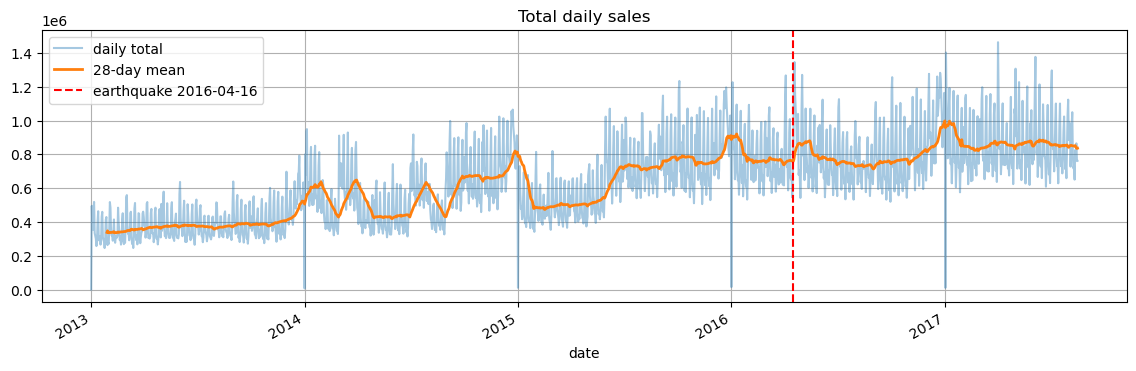

date
2013-01-01     2511.618999
2014-01-01     8602.065404
2015-01-01    12773.616980
2016-01-01    16433.394000
2017-01-01    12082.500997
Name: sales, dtype: float64


In [3]:
daily = train.groupby('date').sales.sum()
ax = daily.plot(alpha=.4, label='daily total')
daily.rolling(28).mean().plot(ax=ax, lw=2, label='28-day mean')
ax.axvline('2016-04-16', color='r', ls='--', label='earthquake 2016-04-16')
ax.set_title('Total daily sales'); ax.legend(); plt.show()

# Sales on Jan 1 of each year (stores are almost all closed)
print(daily[daily.index.strftime('%m-%d') == '01-01'])

## 3. Seasonality: day of week, day of month (paydays), month of year

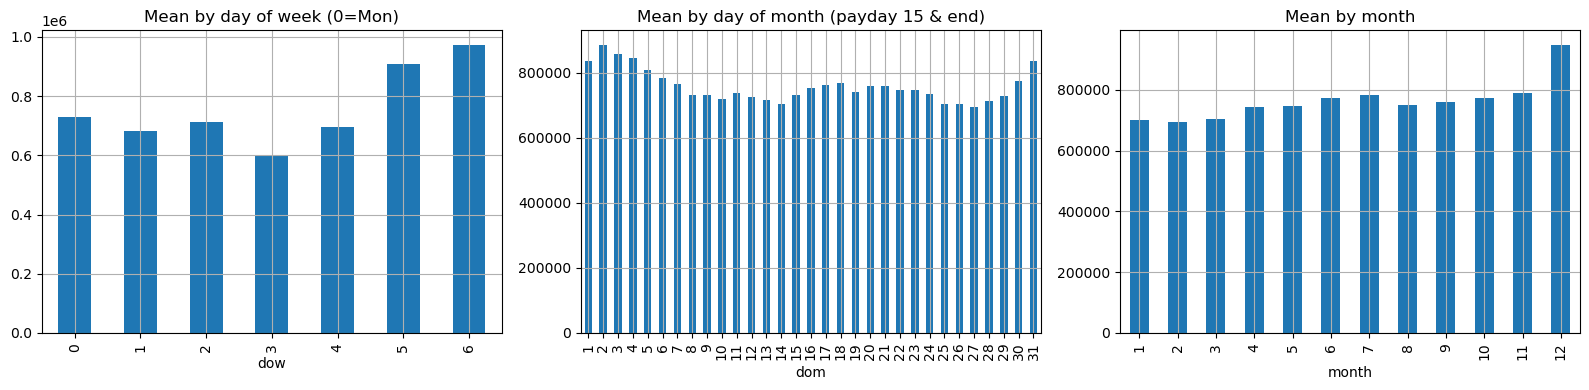

In [4]:
d = daily.to_frame('sales')
d['dow'] = d.index.dayofweek
d['dom'] = d.index.day
d['month'] = d.index.month
d = d[d.index >= '2015-01-01']   # recent data only, to limit the effect of the early trend

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
d.groupby('dow').sales.mean().plot.bar(ax=axes[0], title='Mean by day of week (0=Mon)')
d.groupby('dom').sales.mean().plot.bar(ax=axes[1], title='Mean by day of month (payday 15 & end)')
d.groupby('month').sales.mean().plot.bar(ax=axes[2], title='Mean by month')
plt.tight_layout(); plt.show()

### ACF / PACF
ACF/PACF of the first-differenced log total sales. Spikes at lags 7, 14, 21 indicate strong weekly seasonality.

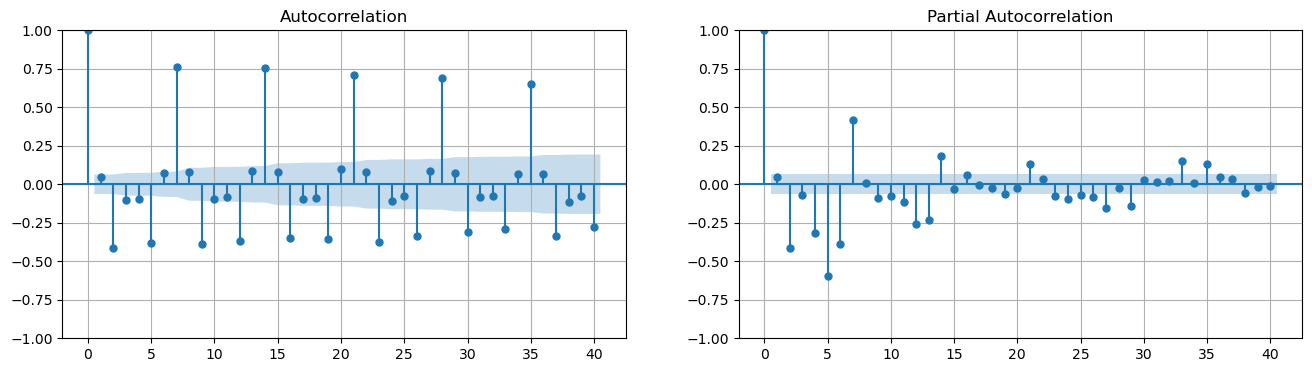

In [5]:
y = np.log1p(daily[daily.index >= '2015-01-01'])
y = y[y.index.strftime('%m-%d') != '01-01']
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
plot_acf(y.diff().dropna(), lags=40, ax=axes[0])
plot_pacf(y.diff().dropna(), lags=40, ax=axes[1], method='ywm')
plt.show()

## 4. Families: which sell the most? do their patterns differ?

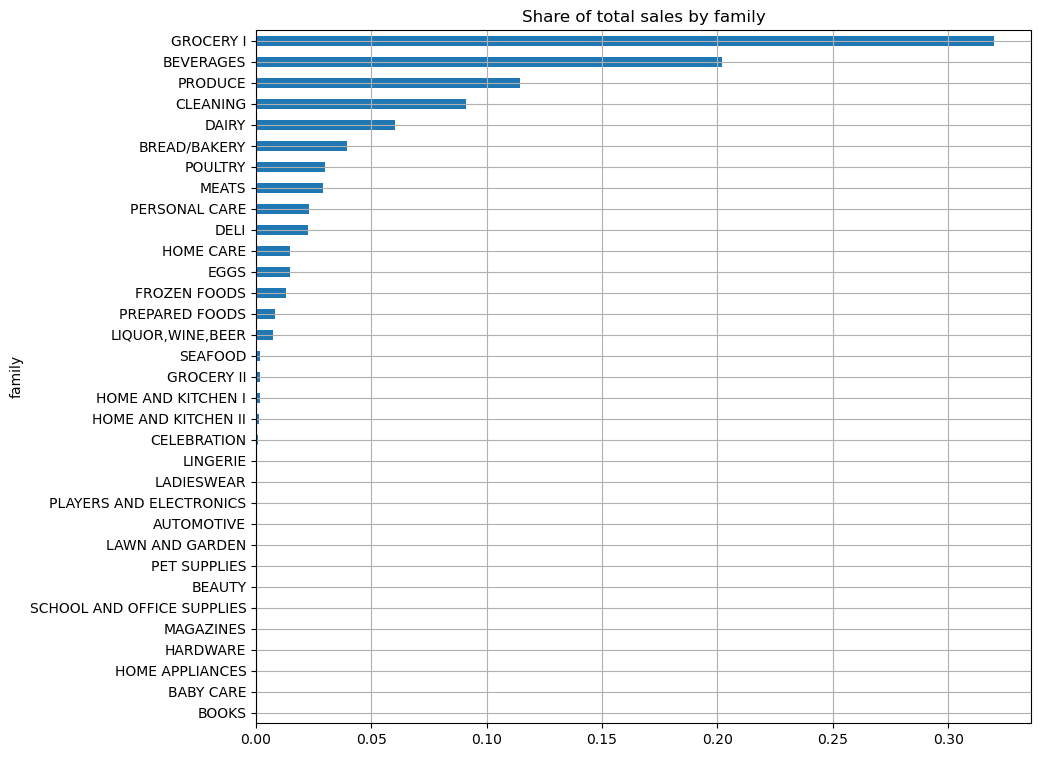

In [6]:
fam = train.groupby('family').sales.sum().sort_values()
(fam / fam.sum()).plot.barh(figsize=(10, 9), title='Share of total sales by family')
plt.show()

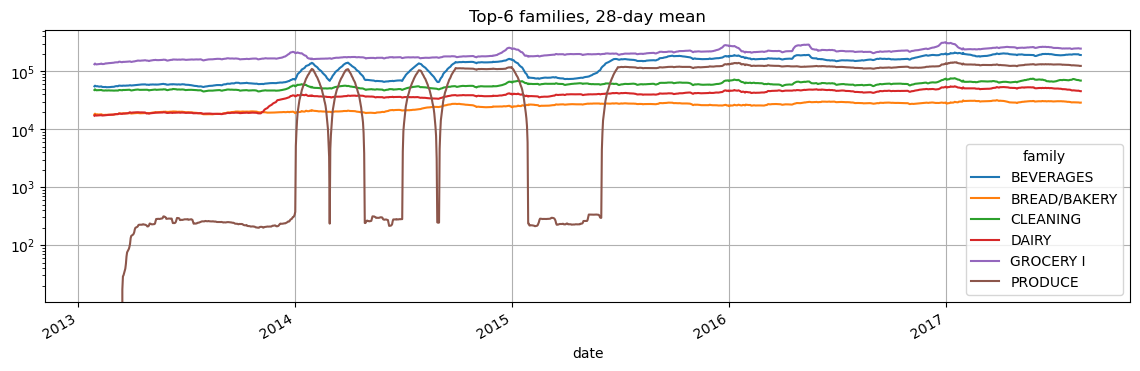

In [7]:
top = fam.index[-6:]
fd = train[train.family.isin(top)].groupby(['date', 'family']).sales.sum().unstack()
fd.rolling(28).mean().plot(title='Top-6 families, 28-day mean', logy=True)
plt.show()

## 5. Zero-sales series: which series are all zero in the last 30 days? (predict 0 directly)

In [8]:
last = train[train.date > train.date.max() - pd.Timedelta(days=30)]
zero = last.groupby(['store_nbr', 'family']).sales.sum()
zero_series = zero[zero == 0]
print('Series with zero sales in the last 30 days:', len(zero_series), '/', len(zero))
print(zero_series.reset_index().family.value_counts())

Series with zero sales in the last 30 days: 111 / 1782
family
BOOKS                         43
BABY CARE                     26
LAWN AND GARDEN               14
SCHOOL AND OFFICE SUPPLIES    11
LADIESWEAR                    11
HOME APPLIANCES                6
Name: count, dtype: int64


In [9]:
# Overall share of zeros
print('Share of rows with sales == 0 in train: %.1f%%' % (100 * (train.sales == 0).mean()))

Share of rows with sales == 0 in train: 31.3%


## 6. Stores: opening dates (first date with positive sales)

In [10]:
first_sale = train[train.sales > 0].groupby('store_nbr').date.min().sort_values()
# All stores are closed on Jan 1, so a store counts as new only if its first sale is after 2013-01-02
print(first_sale[first_sale > '2013-01-02'])
stores.head()

store_nbr
36   2013-05-09
53   2014-05-29
20   2015-02-13
29   2015-03-20
21   2015-07-24
42   2015-08-21
22   2015-10-09
52   2017-04-20
Name: date, dtype: datetime64[ns]


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


## 7. Promotions: does more promotion mean more sales?

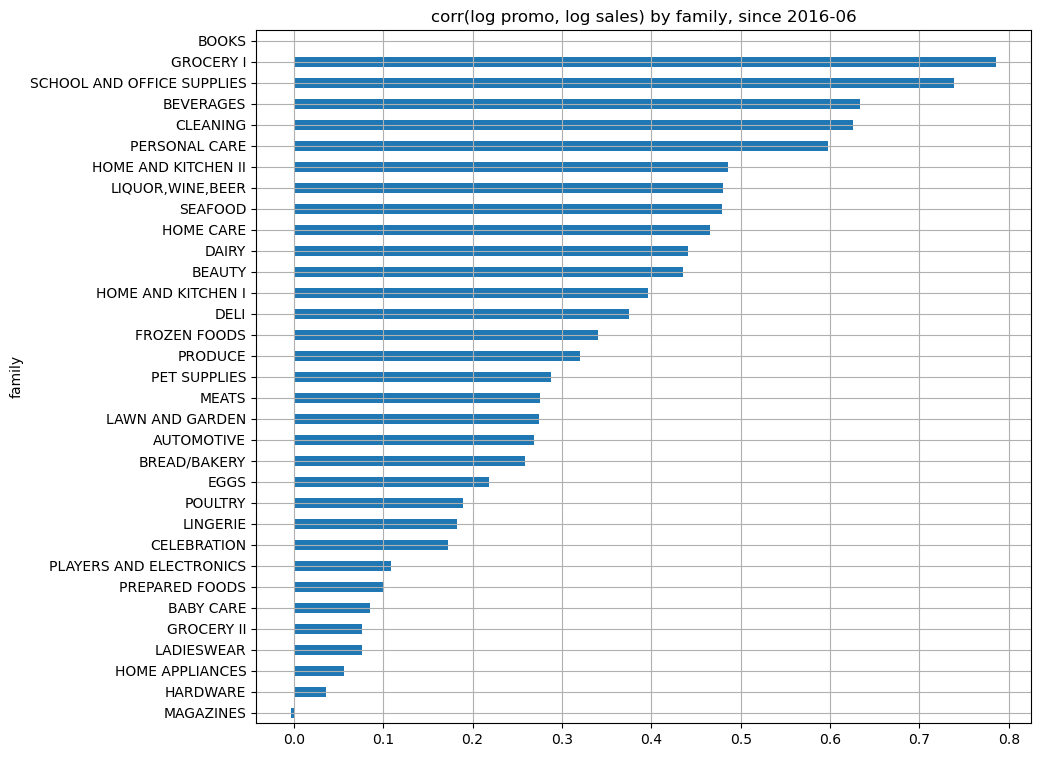

onpromotion is available in test (usable as an exogenous variable): True


In [11]:
recent = train[train.date >= '2016-06-01']
corr = recent.groupby('family').apply(
    lambda g: np.corrcoef(np.log1p(g.onpromotion), np.log1p(g.sales))[0, 1] if g.onpromotion.std() > 0 else np.nan,
    include_groups=False).sort_values()
corr.plot.barh(figsize=(10, 9), title='corr(log promo, log sales) by family, since 2016-06')
plt.show()
print('onpromotion is available in test (usable as an exogenous variable):', 'onpromotion' in test.columns)

## 8. Holidays: how different are holiday sales from normal days?

In [12]:
print(hol.type.value_counts(), '\n')
print(hol.locale.value_counts(), '\n')
print('Rows with transferred=True (not actually a day off):', hol.transferred.sum())

nat = hol[(hol.locale == 'National') & (~hol.transferred) & (hol.type != 'Work Day')]
dd = daily[daily.index >= '2015-01-01'].to_frame('sales')
dd['holiday'] = dd.index.isin(nat.date)
dd['dow'] = dd.index.dayofweek
# Compare within the same weekday to remove the weekly effect
ratio = dd.groupby(['dow', 'holiday']).sales.mean().unstack()
print('\nNational holiday / non-holiday sales ratio, by day of week:')
print((ratio[True] / ratio[False]).round(2))

type
Holiday       221
Event          56
Additional     51
Transfer       12
Bridge          5
Work Day        5
Name: count, dtype: int64 

locale
National    174
Local       152
Regional     24
Name: count, dtype: int64 

Rows with transferred=True (not actually a day off): 12

National holiday / non-holiday sales ratio, by day of week:
dow
0    1.25
1    1.28
2    1.35
3    1.28
4    1.07
5    1.12
6    1.00
dtype: float64


## 9. Oil price: missing values and relationship with sales

Missing oil prices: 43 / 1218
Oil date range: 2013-01-01 -> 2017-08-31 (weekdays only)


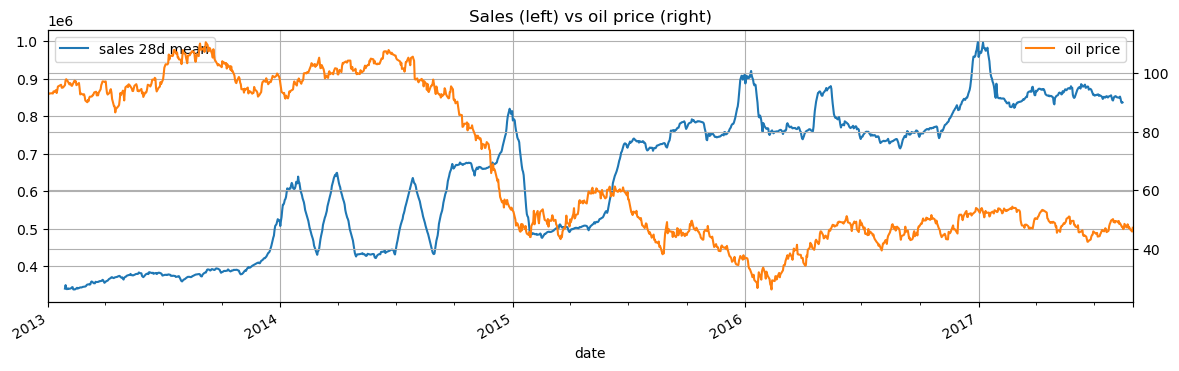

In [13]:
print('Missing oil prices:', oil.dcoilwtico.isna().sum(), '/', len(oil))
print('Oil date range:', oil.date.min().date(), '->', oil.date.max().date(), '(weekdays only)')

o = oil.set_index('date').dcoilwtico.reindex(pd.date_range(oil.date.min(), oil.date.max())).interpolate().bfill()
fig, ax1 = plt.subplots()
daily.rolling(28).mean().plot(ax=ax1, color='C0', label='sales 28d mean')
ax2 = ax1.twinx(); o.plot(ax=ax2, color='C1', label='oil price')
ax1.set_title('Sales (left) vs oil price (right)')
ax1.legend(loc='upper left'); ax2.legend(loc='upper right'); plt.show()

## 10. Transactions: correlated with sales, but not available in the test period (analysis only)

In [14]:
t = trans.groupby('date').transactions.sum()
print('corr(daily transactions, daily sales): %.3f' % t.corr(daily.reindex(t.index)))
print('transactions available in test:', 'transactions' in test.columns)

corr(daily transactions, daily sales): 0.677
transactions available in test: False


## Summary (fill in after reviewing the plots; drives the next steps)

| Question | What I see | Decision |
|---|---|---|
| Trend | | |
| Weekly / monthly / yearly seasonality | | |
| Missing dates, Jan 1 | | |
| Earthquake effect | | |
| Number of zero series | | |
| New stores | | |
| Promotion effect | | |
| Holiday effect | | |
| Oil price | | |
